# Testing ideas to trim down links. 

Last update : 03.26.2025
Version: 0.02 (testing with loops)


<!-- ![Link trimming diagram](../notes/trim_links.jpg) -->
<img src="../notes/trim_links.jpg" alt="Drawing" style="width: 200px;"/>


# Import


In [1]:
#auto reload
%load_ext autoreload
%autoreload 2


In [2]:

import networkx as nx
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt

import gravis as gv

In [3]:
import os
import sys
from pathlib import Path

cwd = os.getcwd()
parent_dir = Path(cwd).parent
# Add the parent directory to the Python path
sys.path.append(str(parent_dir))
print(sys.path)

['/Users/gl665/.pyenv/versions/3.11.8/lib/python311.zip', '/Users/gl665/.pyenv/versions/3.11.8/lib/python3.11', '/Users/gl665/.pyenv/versions/3.11.8/lib/python3.11/lib-dynload', '', '/Users/gl665/Documents/Phrame-MentalMaps-1/.venv/lib/python3.11/site-packages', '/Users/gl665/Documents/Phrame-MentalMaps-1']


In [4]:
from old_code.cld_nx import cld_nx_properties, combine_graphs_with_node_attributes
from old_code import cld_nx

from src.graph_processing.graph_properties import CLDGraph
from src.graph_processing.graph_visual import GraphVisualizer

# Create test graph sets

In [5]:
# create test cases for the link trimming.

G1 = nx.DiGraph()
G1.add_nodes_from(["A", "B", "C", "D"])
G1.add_edge("A", "B", weight=1)
G1.add_edge("B", "C", weight=1)
G1.add_edge("C", "D", weight=1)

G2 = nx.DiGraph()
G2.add_nodes_from(["A", "D"])
G2.add_edge("A", "D", weight=1)

G3 = nx.DiGraph()
G3.add_nodes_from(["A", "C", "D", "E"])
G3.add_edge("A", "C", weight=1)
G3.add_edge("C", "D", weight=1)
G3.add_edge("E", "A", weight=1)

G4 = nx.DiGraph()
G4.add_nodes_from(["A", "E"])
G4.add_edge("A", "E", weight=1)

G_Raw = nx.DiGraph()
G_Raw.add_nodes_from(["A", "B", "C", "D", "E"])
G_Raw.add_edge("A", "B", weight=1)
G_Raw.add_edge("B", "C", weight=1)
G_Raw.add_edge("C", "D", weight=1)
G_Raw.add_edge("A", "D", weight=1)
G_Raw.add_edge("A", "E", weight=1)
G_Raw.add_edge("E", "A", weight=1)

G_Trimmed = nx.DiGraph()
G_Trimmed.add_nodes_from(["A", "C", "D", "E"])
G_Trimmed.add_edge("A", "C", weight=1)
G_Trimmed.add_edge("C", "D", weight=1)
G_Trimmed.add_edge("A", "E", weight=1)
G_Trimmed.add_edge("E", "A", weight=1)


G_test = nx.DiGraph()
G_test.add_nodes_from(["A", "B", "C", "D", "E"])
G_test.add_edge("A", "B", weight=1)
G_test.add_edge("B", "C", weight=1)
G_test.add_edge("C", "D", weight=1)
G_test.add_edge("A", "E", weight=1)
G_test.add_edge("E", "D", weight=1)

In [6]:

G5 = nx.DiGraph()
G5.add_nodes_from(["A", "B", "C", "D"])
G5.add_edge("A", "B", weight=1)
G5.add_edge("B", "C", weight=1)
G5.add_edge("C", "D", weight=1)
G5.add_edge("D", "A", weight=1)

G6 = nx.DiGraph()
G6.add_nodes_from(["A", "B"])
G6.add_edge("A", "B", weight=1)

G7 = nx.DiGraph()
G7.add_nodes_from(["A", "C", "E"])
G7.add_edge("A", "C", weight=1)
G7.add_edge("E", "A", weight=1)

In [7]:
# TODO: translate the strings to numbers to make it faster.
# use jax to make it faster.

In [8]:
# read testing data

from src.data_management.data_loader import DataLoader

save_data = DataLoader()

data = save_data.load_file(
    file_path="/Users/gl665/Documents/Phrame-MentalMaps-1/notebook/data/processed/list_of_org_graphs.pkl")

In [9]:
data[0].edges()

OutEdgeView([('alcohol misuse', 'intimate partner violence'), ('alcohol misuse', 'mental health'), ('alcohol misuse', 'reportable incident to police'), ('alcohol misuse', 'alcohol exposed pregnancy'), ('intimate partner violence', 'alcohol misuse'), ('intimate partner violence', 'mental health'), ('intimate partner violence', 'child welfare system intervention'), ('intimate partner violence', 'reportable incident to police'), ('intimate partner violence', 'dependence on partner'), ('intimate partner violence', 'children witnessing intimate partner violence'), ('intimate partner violence', 'partner control'), ('intimate partner violence', 'perception of getting someone pregnant as ownership of that person'), ('intimate partner violence', 'unresolved trauma'), ('intimate partner violence', 'percieved victimization stigma'), ('mental health', 'alcohol misuse'), ('mental health', 'intimate partner violence'), ('mental health', 'healthy coping skills'), ('reportable incident to police', 're

# Code

In [10]:

def find_reachable_nodes(G, source, target):
    """
    Get all possible direct and indirect links between a source and target node.

    Args:
        G (nx.DiGraph): Input directed graph
        source (str): Source node
        target (str): Target node

    Returns:
        list: List of tuples containing all possible links (direct and indirect) 
              between source and target nodes


    Example:
        Given a graph G with nodes and edges: A -> B -> C -> D

        get_all_simple_paths(G, "A", "D") returns:
        [("A", "B"), ("B", "C"), ("C", "D")]
    """
    paths = list(nx.all_simple_paths(G, source, target))

    # create a list of all the possible links between the source and the target
    all_links = []
    for path in paths:
        for j in path:
            if source != j and path.index(source) < path.index(j):
                all_links.append((source, j))

    return all_links


find_reachable_nodes(G1, "A", "D")
# find_reachable_nodes(G2, "A", "D")
# find_reachable_nodes(G3, "A", "D")
# find_reachable_nodes(G4, "A", "D")

[('A', 'B'), ('A', 'C'), ('A', 'D')]

In [11]:
def get_all_possible_links(G):
    # Get all pairs of nodes at once using list comprehension
    node_pairs = [(source, target) for source in G.nodes()
                  for target in G.nodes() if source != target]

    # Process all pairs in one go using a list comprehension
    all_possible_links = set()
    for source, target in node_pairs:
        all_possible_links.update(find_reachable_nodes(G, source, target))

    return all_possible_links


get_all_possible_links(G1)
# get_all_possible_links(G2)
# get_all_possible_links(G3)
# get_all_possible_links(G4)

{('A', 'B'), ('A', 'C'), ('A', 'D'), ('B', 'C'), ('B', 'D'), ('C', 'D')}

In [12]:

# get all the nodes and store them in numpy array
nodes = np.array(list(G1.nodes()))

# count the sum of the nodes appeared in G1-G4.


def count_node_appearances(list_of_graphs):

    # get all possible nodes in the list of graphs.
    # count the number of times each node appears in the list of graphs.
    # return a dictioary of the node name as key and the count as value.
    all_nodes = ()
    for graph in list_of_graphs:
        print("graph nodes: ", graph.nodes())
        all_nodes = set(all_nodes).union(graph.nodes())

    # count the number of times each node appears in the list of graphs.
    node_counts = {}
    for node in all_nodes:
        node_counts[node] = sum(node in graph.nodes()
                                for graph in list_of_graphs)

    return node_counts


node_counts = count_node_appearances([G1, G2, G3, G4])
print("node_counts: ", node_counts)
print("node_counts keys: ", list(node_counts.keys()))
print("node_counts values: ", np.array(list(node_counts.values())))

graph nodes:  ['A', 'B', 'C', 'D']
graph nodes:  ['A', 'D']
graph nodes:  ['A', 'C', 'D', 'E']
graph nodes:  ['A', 'E']
node_counts:  {'C': 2, 'D': 3, 'A': 4, 'B': 1, 'E': 2}
node_counts keys:  ['C', 'D', 'A', 'B', 'E']
node_counts values:  [2 3 4 1 2]


In [13]:
def trim_nodes(list_of_graphs, trim_node_threshold=1):

    nodeCounts = count_node_appearances(list_of_graphs)

    trimNodes = {node: count for node, count in nodeCounts.items()
                 if count > trim_node_threshold}

    return trimNodes


trimmed_nodes = trim_nodes([G1, G2, G3, G4], 1)
print(trimmed_nodes)

graph nodes:  ['A', 'B', 'C', 'D']
graph nodes:  ['A', 'D']
graph nodes:  ['A', 'C', 'D', 'E']
graph nodes:  ['A', 'E']
{'C': 2, 'D': 3, 'A': 4, 'E': 2}


In [14]:
def count_edge_appearances(list_of_graphs):

    for graph in list_of_graphs:

        # all_possible_edges = ()

        # for graph in list_of_graphs:
        #     all_possible_edges = set(all_possible_edges).union(
        #         get_all_possible_links(graph))

        # print(all_possible_edges)

        edge_counts = defaultdict(int)
        for graph in list_of_graphs:
            for link in get_all_possible_links(graph):
                if link in edge_counts:
                    edge_counts[link] += 1
                else:
                    edge_counts[link] = 1
    print(edge_counts)
    return edge_counts


count_edge_appearances([G1, G2, G3, G4])

defaultdict(<class 'int'>, {('A', 'C'): 2, ('A', 'B'): 1, ('B', 'D'): 1, ('C', 'D'): 2, ('B', 'C'): 1, ('A', 'D'): 3, ('E', 'D'): 1, ('E', 'A'): 1, ('E', 'C'): 1, ('A', 'E'): 1})


defaultdict(int,
            {('A', 'C'): 2,
             ('A', 'B'): 1,
             ('B', 'D'): 1,
             ('C', 'D'): 2,
             ('B', 'C'): 1,
             ('A', 'D'): 3,
             ('E', 'D'): 1,
             ('E', 'A'): 1,
             ('E', 'C'): 1,
             ('A', 'E'): 1})

In [15]:
def trim_edges(list_of_graphs, trimmed_nodes, trim_edge_threshold=0):
    edgeCounts = count_edge_appearances(list_of_graphs)

    trimEdges = {}
    for edge, count in edgeCounts.items():
        if (edge[0] in trimmed_nodes or edge[1] in trimmed_nodes) and count > trim_edge_threshold:
            trimEdges[edge] = count

    return trimEdges


trimmedGraph = trim_edges([G1, G2, G3, G4], trimmed_nodes, 1)
print("trimmedGraph: ", trimmedGraph)

defaultdict(<class 'int'>, {('A', 'C'): 2, ('A', 'B'): 1, ('B', 'D'): 1, ('C', 'D'): 2, ('B', 'C'): 1, ('A', 'D'): 3, ('E', 'D'): 1, ('E', 'A'): 1, ('E', 'C'): 1, ('A', 'E'): 1})
trimmedGraph:  {('A', 'C'): 2, ('C', 'D'): 2, ('A', 'D'): 3}


In [16]:
# turn the trimmedGraph back to a graph
# translate the trimmedGraph to a list of tuples
allEdges = []
for edge, count in trimmedGraph.items():
    EdgeWWeight = (edge[0], edge[1], count)
    allEdges.append(EdgeWWeight)


trimmedGraph = nx.DiGraph()
trimmedGraph.add_weighted_edges_from(allEdges)

# print the trimmedGraph
print(trimmedGraph.nodes())
print(trimmedGraph.edges())

['A', 'C', 'D']
[('A', 'C'), ('A', 'D'), ('C', 'D')]


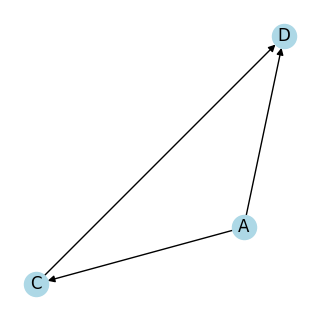

In [17]:
# print nx graph
# change the size of the graph

plt.figure(figsize=(3, 3))

nx.draw(trimmedGraph, with_labels=True, node_color="lightblue")

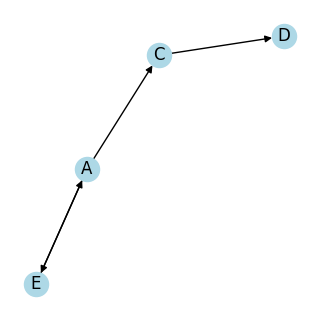

In [18]:
plt.figure(figsize=(3, 3))
nx.draw(G_Trimmed, with_labels=True, node_color="lightblue")

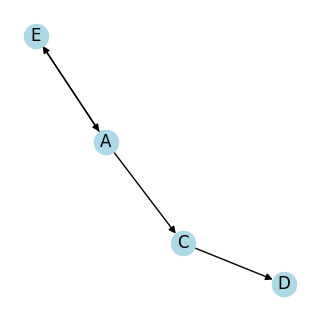

In [19]:
plt.figure(figsize=(3, 3))
nx.draw(G_Trimmed, with_labels=True, node_color="lightblue")

In [20]:
edge = ("A", "B")

if "C" in edge:
    print(True)
else:

    print(False)

for i in edge:
    print(i)

False
A
B


# The class for the functions above

In [21]:
class LinkTrimmer:
    def __init__(self, list_of_graphs):
        self.list_of_graphs = list_of_graphs

    def count_node_appearances(self):
        """
        Count the number of times each node appears in the list of graphs.
        :param list_of_graphs: list of graphs
        :return: dictionary of node counts, key is the node name, value is the count
        """

        all_nodes = ()
        for graph in list_of_graphs:
            # print("graph nodes: ", graph.nodes())
            all_nodes = set(all_nodes).union(graph.nodes())

        # count the number of times each node appears in the list of graphs.
        node_counts = {}
        for node in all_nodes:
            node_counts[node] = sum(node in graph.nodes()
                                    for graph in list_of_graphs)

        return node_counts

    def count_edge_appearances(self):
        """
        Count the number of times each edge appears in the list of graphs.
        :param list_of_graphs: list of graphs
        :return: dictionary of edge counts, key is the edge, value is the count
        """
        for graph in list_of_graphs:

            edge_counts = defaultdict(int)
            for graph in list_of_graphs:
                for link in get_all_possible_links(graph):
                    if link in edge_counts:
                        edge_counts[link] += 1
                    else:
                        edge_counts[link] = 1

        return edge_counts

    def trim_nodes(self, trim_node_threshold=0):

        nodeCounts = self.count_node_appearances()
        trimmedNodes = {node: count for node,
                        count in nodeCounts.items() if count > trim_node_threshold}

        return trimmedNodes

    def trim_edges(self, trim_edge_threshold=0, trim_nodes_threshold=0):
        """
        Trim the edges of the graph based on the edge count.
        :param trimmed_nodes: dictionary of trimmed nodes
        :param trim_edge_threshold: threshold for the edge count
        :return: dictionary of trimmed edges, key is the edge, value is the count
        """
        edgeCounts = self.count_edge_appearances()
        trimmed_nodes = self.trim_nodes(trim_nodes_threshold)

        trimmedEdges = {}
        for edge, count in edgeCounts.items():
            if (edge[0] in trimmed_nodes or edge[1] in trimmed_nodes) and count > trim_edge_threshold:
                trimmedEdges[edge] = count

        return trimmedEdges

    def get_trimmed_graph(self, trimmed_edges_threshold=0, trimmed_nodes_threshold=0):
        """
        Get the trimmed graph from the list of graphs.
        :return: trimmed graph
        """
        allEdges = []
        for edge, count in self.trim_edges(trimmed_edges_threshold, trimmed_nodes_threshold).items():
            EdgeWWeight = (edge[0], edge[1], count)
            allEdges.append(EdgeWWeight)

        trimmedGraph = nx.DiGraph()
        trimmedGraph.add_weighted_edges_from(allEdges)
        return trimmedGraph

# Run Code

In [22]:
save_data = DataLoader()

data = save_data.load_file(
    file_path="/Users/gl665/Documents/Phrame-MentalMaps-1/notebook/data/processed/list_of_org_graphs.pkl")

print(data)

[<networkx.classes.digraph.DiGraph object at 0x169007050>, <networkx.classes.digraph.DiGraph object at 0x16af94990>, <networkx.classes.digraph.DiGraph object at 0x16afa2a90>, <networkx.classes.digraph.DiGraph object at 0x16af70d90>, <networkx.classes.digraph.DiGraph object at 0x16af3ca90>, <networkx.classes.digraph.DiGraph object at 0x16af342d0>, <networkx.classes.digraph.DiGraph object at 0x16af0e650>, <networkx.classes.digraph.DiGraph object at 0x16af0b8d0>, <networkx.classes.digraph.DiGraph object at 0x16af19bd0>, <networkx.classes.digraph.DiGraph object at 0x16afb4a10>, <networkx.classes.digraph.DiGraph object at 0x16b007310>, <networkx.classes.digraph.DiGraph object at 0x16b020dd0>, <networkx.classes.digraph.DiGraph object at 0x16b033ad0>, <networkx.classes.digraph.DiGraph object at 0x16b04d6d0>, <networkx.classes.digraph.DiGraph object at 0x16b070c90>, <networkx.classes.digraph.DiGraph object at 0x16b091c90>]


In [28]:

list_of_graphs = [G1, G2, G3, G4]
# list_of_graphs = data


link_trimmer = LinkTrimmer(list_of_graphs)
trimmedGraph = link_trimmer.get_trimmed_graph(
    trimmed_edges_threshold=1, trimmed_nodes_threshold=1)


trimmed_graph = CLDGraph(trimmedGraph)
trimmed_graph.build_CLD_graph()


print(trimmed_graph.graph_properties())

print(trimmed_graph.node_properties())
print(trimmed_graph.edge_properties())

# graph_print = GraphVisualizer(
#     trimmed_graph, edge_colors='blue', node_colors='lightblue')

# # graph_print.gravis_settings()

# # gv.d3(graph_print)

# graph_print.visualize_networkx()

{'type': <class 'src.graph_processing.graph_properties.CLDGraph'>, 'directed': True, 'num_nodes': 3, 'num_edges': 3}
{'A': {'type': "<class 'str'>", 'attributes': {}, 'degree': 2}, 'C': {'type': "<class 'str'>", 'attributes': {}, 'degree': 2}, 'D': {'type': "<class 'str'>", 'attributes': {}, 'degree': 2}}
{('A', 'C'): {'weight': 2}, ('A', 'D'): {'weight': 3}, ('C', 'D'): {'weight': 2}}


{'E': 2, 'C': 2, 'A': 4, 'B': 1, 'D': 3}
defaultdict(<class 'int'>, {('C', 'D'): 2, ('A', 'C'): 2, ('B', 'C'): 1, ('A', 'D'): 3, ('B', 'D'): 1, ('A', 'B'): 1, ('E', 'C'): 1, ('E', 'D'): 1, ('E', 'A'): 1, ('A', 'E'): 1})
trimmed_nodes:  {'E': 2, 'C': 2, 'A': 4, 'D': 3}
trimmed_edges:  {('C', 'D'): 2, ('A', 'C'): 2, ('A', 'D'): 3}


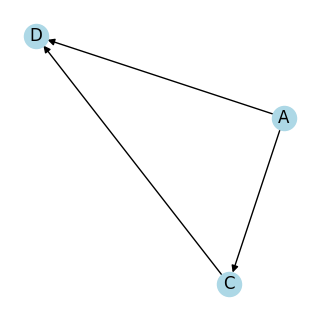

In [ ]:

# print(link_trimmer.count_node_appearances())
# print(link_trimmer.count_edge_appearances())
# trimmed_nodes = link_trimmer.trim_nodes(trim_node_threshold=1)
# print("trimmed_nodes: ", trimmed_nodes)
# trimmed_edges = link_trimmer.trim_edges(
#     trim_edge_threshold=1, trim_nodes_threshold=1)
# print("trimmed_edges: ", trimmed_edges)

# trimmedGraph = link_trimmer.get_trimmed_graph(
#     trimmed_edges_threshold=1, trimmed_nodes_threshold=1)

# plt.figure(figsize=(3, 3))

# nx.draw(trimmed_graph, with_labels=True, node_color="lightblue")

In [255]:

# Set thresholds
edge_threshold = 1
node_threshold = 1

# Get trimmed graph
trimmed_graph = trimmer.get_trimmed_graph(
    trimmed_edges_threshold=edge_threshold,
    trimmed_nodes_threshold=node_threshold
)

# Print graph info
print("Trimmed Graph Properties:")
print(f"Number of nodes: {trimmed_graph.number_of_nodes()}")
print(f"Number of edges: {trimmed_graph.number_of_edges()}")
print("\nEdges with weights:")
for u, v, w in trimmed_graph.edges(data='weight'):
    print(f"{u} -> {v}: {w}")

trimmed_graph = CLDGraph(trimmed_graph)

trimmed_graph.graph_properties()

Trimmed Graph Properties:
Number of nodes: 9
Number of edges: 30

Edges with weights:
partner control -> birth control use: 2
partner control -> pregnancy: 2
partner control -> alcohol exposed pregnancy: 2
birth control use -> alcohol exposed pregnancy: 2
birth control use -> pregnancy: 2
intimate partner violence -> birth control use: 2
intimate partner violence -> partner control: 2
intimate partner violence -> mental health: 2
intimate partner violence -> alcohol exposed pregnancy: 2
intimate partner violence -> pregnancy: 2
intimate partner violence -> alcohol misuse: 2
intimate partner violence -> child welfare system intervention: 2
mental health -> pregnancy: 2
mental health -> alcohol misuse: 2
mental health -> alcohol exposed pregnancy: 2
mental health -> birth control use: 2
mental health -> child welfare system intervention: 2
mental health -> partner control: 2
mental health -> intimate partner violence: 2
pregnancy -> alcohol exposed pregnancy: 2
alcohol misuse -> mental h

In [259]:
G = cld_nx.clean_graph_for_gravis(trimmed_graph)


print(G)
cld_nx.gravis_settings(G)


# gv.d3(G)

CLDGraph with 9 nodes and 30 edges


In [ ]:
gv.d3(G)

# ignore

In [6]:
# read testing data

from src.data_management.data_loader import DataLoader

save_data = DataLoader()

source_graph = save_data.load_file(
    file_path="/Users/gl665/Documents/Phrame-MentalMaps-1/notebook/data/processed/trimmed_graph.pkl")


{'type': src.graph_processing.cld_aggregator.CLDGraph,
 'directed': True,
 'num_nodes': 52,
 'num_edges': 71}

In [60]:
trimmed_graph = CLDGraph(source_graph)
trimmed_graph.get_nx_graph()


trimmed_graph.graph_properties()
# trimmed_graph.node_properties()
# trimmed_graph.edge_properties()

{'type': src.graph_processing.cld_aggregator.CLDGraph,
 'directed': True,
 'num_nodes': 52,
 'num_edges': 71}

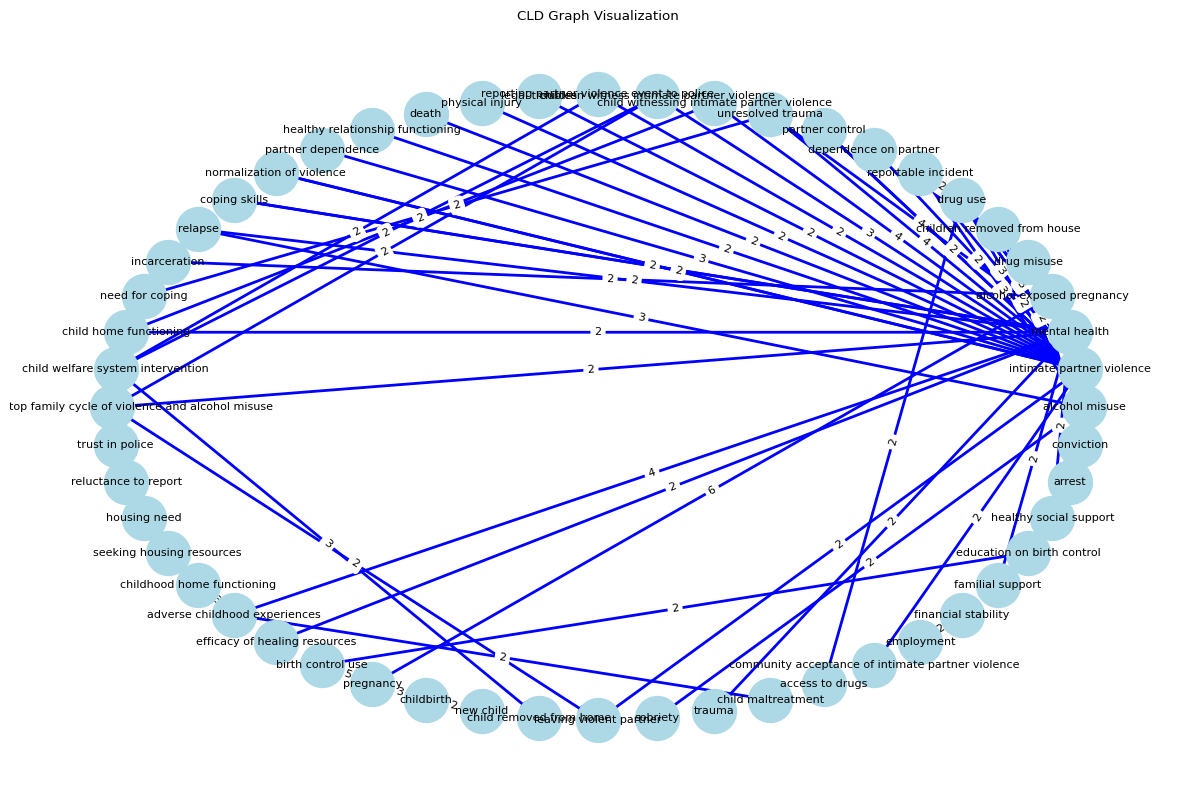

In [61]:
graph_print = GraphVisualizer(
    trimmed_graph, edge_colors='blue', node_colors='lightblue')
graph_print.visualize_networkx()

In [249]:
G = cld_nx.clean_graph_for_gravis(trimmed_graph)


cld_nx.gravis_settings(G)


gv.d3(G)